# 07 · Decision rules and next experiments

Eight clean sinusoidal prototypes combine four unoriented wavevector axes and two integer scale factors. Queries have a random phase, random contrast sign and four additive-noise levels. Each observable independently ranks the same gallery by relative distance. Exact or near ties share credit. We score joint identity, axis label and scale label separately.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

In [3]:
from observables.benchmark import evaluate,summarize
queries=evaluate(replicates=30,seed=701)
summary=summarize(queries)
queries.to_csv(OUT/'retrieval_queries.csv',index=False)
summary.to_csv(OUT/'retrieval_summary.csv',index=False)
display(summary.query('noise_sd==0').pivot(index='metric',columns='endpoint',values='estimate').round(3))

endpoint,axis_hit,joint,scale_hit
metric,,,
Q,1.000,0.500,0.500
fourth,0.500,0.250,0.500
pixels,0.579,0.508,0.719
power,1.000,1.000,1.000
radial power,0.500,0.500,1.000


## Read performance against the chosen label
The gallery has eight joint types, four axis labels and two scale labels. Random expectations are 1/8, 1/4 and 1/2. Scale means multiplying the integer wavevector by 4 or 8; diagonal and axial wavevectors have different Euclidean magnitudes at the same scale label. The profiles are fixed before the query set is generated. There is no fitted combination or selected threshold.

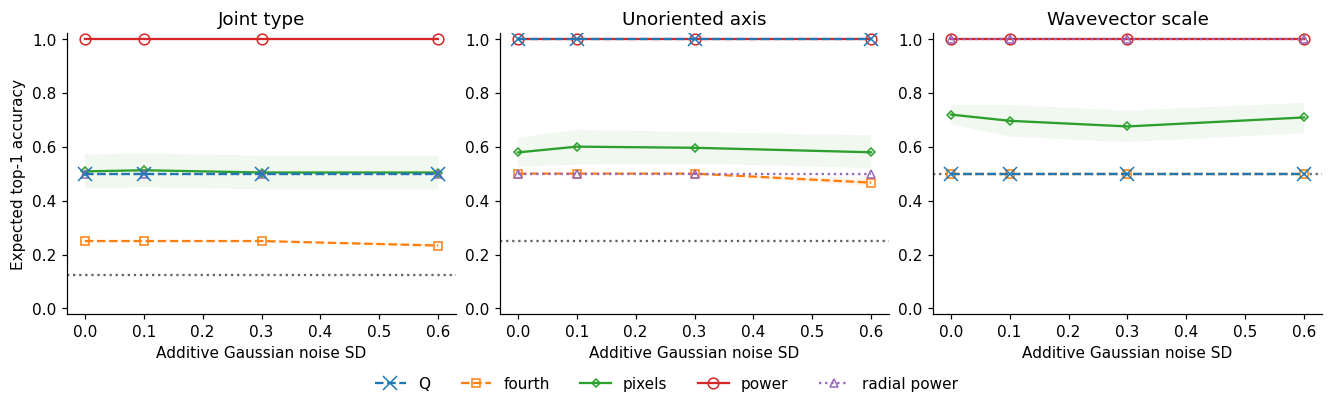

Independent base queries: 240 · noise views per query: 4


In [5]:
fig,axes=plt.subplots(1,3,figsize=(12,3.6))
for ax,endpoint,title,chance in zip(axes,['joint','axis_hit','scale_hit'],['Joint type','Unoriented axis','Wavevector scale'],[.125,.25,.5]):
    for metric,g in summary[summary.endpoint==endpoint].groupby('metric'):
        style={'Q':('x','--',9),'fourth':('s','--',5),'pixels':('D','-',4),
               'power':('o','-',7),'radial power':('^',':',5)}[metric]
        ax.plot(g.noise_sd,g.estimate,marker=style[0],ls=style[1],markersize=style[2],
                markerfacecolor='none',label=metric,zorder=10 if metric=='Q' else 3)
        ax.fill_between(g.noise_sd.to_numpy(),g.low95.to_numpy(),g.high95.to_numpy(),alpha=.07)
    ax.axhline(chance,ls=':',color='.4');ax.set(ylim=(-.02,1.02),xlabel='Additive Gaussian noise SD',title=title)
axes[0].set_ylabel('Expected top-1 accuracy')
fig.legend(*axes[-1].get_legend_handles_labels(),loc='outside lower center',ncol=5,frameon=False)
show('07_retrieval')
print('Independent base queries:',queries.source.nunique(),'· noise views per query:',queries.noise_sd.nunique())

## What can be concluded?
Full spectral agreement is well suited to these periodic wave labels. Q captures an axis but pools away spacing. Fourth angular order makes perpendicular axes equivalent. Radial power retains frequency shells while pooling direction. Pixel comparison retains phase that the task declares irrelevant. These are consequences of observable invariances.

Intervals use 2,000 stratified bootstrap resamples of base sources, preserving the eight prototype types. Marginal intervals at each noise level condition on the gallery, pattern family and chosen representation. The 240 sources are synthetic independent draws of phase, sign and noise; they do not represent 240 natural objects.

In [7]:
clean=summary.query("noise_sd==0").set_index(['metric','endpoint']).estimate
assert np.isclose(clean['power','joint'],1)
assert np.isclose(clean['Q','axis_hit'],1)
assert np.isclose(clean['Q','scale_hit'],.5)
assert np.isclose(clean['fourth','axis_hit'],.5)
assert np.isclose(clean['radial power','joint'],.5)
display(summary.query("noise_sd==0.6").pivot(index='metric',columns='endpoint',values='estimate').round(3))

endpoint,axis_hit,joint,scale_hit
metric,,,
Q,1.000,0.500,0.500
fourth,0.467,0.233,0.500
pixels,0.579,0.504,0.708
power,1.000,1.000,1.000
radial power,0.500,0.500,1.000


## Research program after the foundation stage
1. **Representations.** Repeat the same controlled distinctions with local gradients, patch features and whole-object vectors. Audit which information each representation retains before comparing observables.
2. **Spatial hierarchy.** Compare angular orders at multiple grid sizes and correlation separations. Use translated and rotated controls to quantify the price of positional specificity.
3. **Higher correlations.** Search for new collisions under the chosen observable set. Test third-order spatial correlations and mixed position–orientation statistics with finite-sample uncertainty.
4. **Learned representations.** Freeze an encoder and learn any profile weights using separate development sources. Evaluate on held-out structures and distribution shifts. Compare to cosine, histogram/HOG-style descriptors, second-moment pooling and spectral baselines.
5. **Explanation.** Generate counterfactual pairs that alter one known property, test whether the relevant component responds, and measure cross-component responses. Statements about category or meaning require independently supplied labels.
6. **Decision stage.** Separate label-specific predictive utility from observable resolving power. Use paired source-level comparisons and account for selecting orders, scales and weights.

A successful foundational result can be an exact collision, an invariance proof or a calibrated null. Any claim that this framework improves real-world recognition awaits later experiments.